In the telecommunications sector, churn is a measure of the number of customers leaving an operator.
Customers may be leaving for various reasons, such as finding lower prices in the competition or being
unhappy with the service provided. Therefore, as in any other business area, it is imperative for a telecom
operator to have models capable of predicting customer churn, i.e., the likelihood of a customer leaving. This
will allow the operator to retain customers by offering better services or more attractive prices before they
choose to leave.

Download the two datasets containing data from a telecommunications operator. The first, CallsData
(https://goo.gl/BSUhZ3), contains call data from a customer, and the second, ContractData
(https://goo.gl/YZLDPf), contains a contract data.
A value of churn = 0 means that the customer has remained with the operator, while a value of churn = 1
means that the customer left the operator.

In [1]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix
from sklearn.metrics import recall_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.metrics import f1_score
from sklearn.metrics import fbeta_score
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

from sklearn.model_selection import cross_val_score

## T1 :
Load the datasets and merge them by “Area Code” and “Phone”. Then transform the “Churn” attribute
into a nominal attribute;

In [3]:
ds_calls = pd.read_csv("datasets/CallsData.csv")
ds_contracts = pd.read_csv("datasets/ContractData.csv")

In [4]:
ds_calls.head()

,VMail Message,Day Mins,Eve Mins,Night Mins,Intl Mins,CustServ Calls,Day Calls,Day Charge,Eve Calls,Eve Charge,Night Calls,Night Charge,Intl Calls,Intl Charge,Area Code,Phone
0,25,265.1,197.4,244.7,10.0,1,110,45.07,99,16.78,91,11.01,3,2.70,415,382-4657
1,26,161.6,195.5,254.4,13.7,1,123,27.47,103,16.62,103,11.45,3,3.70,415,371-7191
2,0,243.4,121.2,162.6,12.2,0,114,41.38,110,10.30,104,7.32,5,3.29,415,358-1921
3,0,299.4,61.9,196.9,6.6,2,71,50.90,88,5.26,89,8.86,7,1.78,408,375-9999
4,0,166.7,148.3,186.9,10.1,3,113,28.34,122,12.61,121,8.41,3,2.73,415,330-6626


In [5]:
ds_contracts.head()

,Account Length,Churn,Int'l Plan,VMail Plan,State,Area Code,Phone
0,128,0,0,1,KS,415,382-4657
1,107,0,0,1,OH,415,371-7191
2,137,0,0,0,NJ,415,358-1921
3,84,0,1,0,OH,408,375-9999
4,75,0,1,0,OK,415,330-6626


In [22]:
ds_merged = pd.merge(ds_calls, ds_contracts, on=['Area Code', 'Phone'], how='left')
ds_merged.head()

,VMail Message,Day Mins,Eve Mins,Night Mins,Intl Mins,CustServ Calls,Day Calls,Day Charge,Eve Calls,Eve Charge,...,Night Charge,Intl Calls,Intl Charge,Area Code,Phone,Account Length,Churn,Int'l Plan,VMail Plan,State
0,25,265.1,197.4,244.7,10.0,1,110,45.07,99,16.78,...,11.01,3,2.70,415,382-4657,128,0,0,1,KS
1,26,161.6,195.5,254.4,13.7,1,123,27.47,103,16.62,...,11.45,3,3.70,415,371-7191,107,0,0,1,OH
2,0,243.4,121.2,162.6,12.2,0,114,41.38,110,10.30,...,7.32,5,3.29,415,358-1921,137,0,0,0,NJ
3,0,299.4,61.9,196.9,6.6,2,71,50.90,88,5.26,...,8.86,7,1.78,408,375-9999,84,0,1,0,OH
4,0,166.7,148.3,186.9,10.1,3,113,28.34,122,12.61,...,8.41,3,2.73,415,330-6626,75,0,1,0,OK


In [23]:
## Não existem chaves duplicadas, por isso não se perdeu informação com o merge
print(ds_calls.shape)
print(ds_contracts.shape)
print(ds_merged.shape)

(3333, 16)
(3333, 7)
(3333, 21)


In [24]:
ds_merged.info()

<class 'pandas.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   VMail Message   3333 non-null   int64  
 1   Day Mins        3333 non-null   float64
 2   Eve Mins        3333 non-null   float64
 3   Night Mins      3333 non-null   float64
 4   Intl Mins       3333 non-null   float64
 5   CustServ Calls  3333 non-null   int64  
 6   Day Calls       3333 non-null   int64  
 7   Day Charge      3333 non-null   float64
 8   Eve Calls       3333 non-null   int64  
 9   Eve Charge      3333 non-null   float64
 10  Night Calls     3333 non-null   int64  
 11  Night Charge    3333 non-null   float64
 12  Intl Calls      3333 non-null   int64  
 13  Intl Charge     3333 non-null   float64
 14  Area Code       3333 non-null   int64  
 15  Phone           3333 non-null   str    
 16  Account Length  3333 non-null   int64  
 17  Churn           3333 non-null   int64  
 18 

In [26]:
# remover features categóricas do merged
ds_cleaned = ds_merged.drop(['Phone', 'State'], axis=1)
ds_cleaned.info()

<class 'pandas.DataFrame'>
RangeIndex: 3333 entries, 0 to 3332
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   VMail Message   3333 non-null   int64  
 1   Day Mins        3333 non-null   float64
 2   Eve Mins        3333 non-null   float64
 3   Night Mins      3333 non-null   float64
 4   Intl Mins       3333 non-null   float64
 5   CustServ Calls  3333 non-null   int64  
 6   Day Calls       3333 non-null   int64  
 7   Day Charge      3333 non-null   float64
 8   Eve Calls       3333 non-null   int64  
 9   Eve Charge      3333 non-null   float64
 10  Night Calls     3333 non-null   int64  
 11  Night Charge    3333 non-null   float64
 12  Intl Calls      3333 non-null   int64  
 13  Intl Charge     3333 non-null   float64
 14  Area Code       3333 non-null   int64  
 15  Account Length  3333 non-null   int64  
 16  Churn           3333 non-null   int64  
 17  Int'l Plan      3333 non-null   int64  
 18 

In [30]:
#Converter Churn em nominal. Originalmente como inteiro deve ser sinalizada como nominal e não como medida.
ds_cleaned["Churn"] = ds_cleaned["Churn"].astype("category")
ds_cleaned

,VMail Message,Day Mins,Eve Mins,Night Mins,Intl Mins,CustServ Calls,Day Calls,Day Charge,Eve Calls,Eve Charge,Night Calls,Night Charge,Intl Calls,Intl Charge,Area Code,Account Length,Churn,Int'l Plan,VMail Plan
0,25,265.1,197.4,244.7,10.0,1,110,45.07,99,16.78,91,11.01,3,2.70,415,128,0,0,1
1,26,161.6,195.5,254.4,13.7,1,123,27.47,103,16.62,103,11.45,3,3.70,415,107,0,0,1
2,0,243.4,121.2,162.6,12.2,0,114,41.38,110,10.30,104,7.32,5,3.29,415,137,0,0,0
3,0,299.4,61.9,196.9,6.6,2,71,50.90,88,5.26,89,8.86,7,1.78,408,84,0,1,0
4,0,166.7,148.3,186.9,10.1,3,113,28.34,122,12.61,121,8.41,3,2.73,415,75,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3328,36,156.2,215.5,279.1,9.9,2,77,26.55,126,18.32,83,12.56,6,2.67,415,192,0,0,1
3329,0,231.1,153.4,191.3,9.6,3,57,39.29,55,13.04,123,8.61,4,2.59,415,68,0,0,0
3330,0,180.8,288.8,191.9,14.1,2,109,30.74,58,24.55,91,8.64,6,3.81,510,28,0,0,0
3331,0,213.8,159.6,139.2,5.0,2,105,36.35,84,13.57,137,6.26,10,1.35,510,184,0,1,0


In [31]:
# remover o Area Code porque não é um medida mas um identificador
ds_final = ds_cleaned.drop('Area Code', axis=1)
ds_final

,VMail Message,Day Mins,Eve Mins,Night Mins,Intl Mins,CustServ Calls,Day Calls,Day Charge,Eve Calls,Eve Charge,Night Calls,Night Charge,Intl Calls,Intl Charge,Account Length,Churn,Int'l Plan,VMail Plan
0,25,265.1,197.4,244.7,10.0,1,110,45.07,99,16.78,91,11.01,3,2.70,128,0,0,1
1,26,161.6,195.5,254.4,13.7,1,123,27.47,103,16.62,103,11.45,3,3.70,107,0,0,1
2,0,243.4,121.2,162.6,12.2,0,114,41.38,110,10.30,104,7.32,5,3.29,137,0,0,0
3,0,299.4,61.9,196.9,6.6,2,71,50.90,88,5.26,89,8.86,7,1.78,84,0,1,0
4,0,166.7,148.3,186.9,10.1,3,113,28.34,122,12.61,121,8.41,3,2.73,75,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3328,36,156.2,215.5,279.1,9.9,2,77,26.55,126,18.32,83,12.56,6,2.67,192,0,0,1
3329,0,231.1,153.4,191.3,9.6,3,57,39.29,55,13.04,123,8.61,4,2.59,68,0,0,0
3330,0,180.8,288.8,191.9,14.1,2,109,30.74,58,24.55,91,8.64,6,3.81,28,0,0,0
3331,0,213.8,159.6,139.2,5.0,2,105,36.35,84,13.57,137,6.26,10,1.35,184,0,1,0


## T2:
Use a Decision Tree as a classifier (sklearn.tree.DecisionTreeClassifier) and evaluate the model’s accuracy
in predicting the churn. Also evaluate the model using the f1_macro metric. Use 10-fold cross validation;
Note: define X and y, paying attention to the type of attributes that are part of X.


In [34]:
X = ds_final.drop('Churn', axis=1)
y = ds_final['Churn'].to_frame()
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25,random_state=2021)
clf = DecisionTreeClassifier(random_state=2021)

In [35]:
clf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",2021
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

In [36]:
predictions = clf.predict(X_test)
predictions

array([0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1,
       0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1,

In [37]:
print(y_test.values.shape)

(834,)


In [38]:
confusion_matrix(y_test, predictions)

array([[692,  32],
       [ 29,  81]])

In [39]:
accuracy_score(y_test, predictions)

0.9268585131894485

In [40]:
precision_score(y_test, predictions)

0.7168141592920354

In [41]:
recall_score(y_test, predictions)

0.7363636363636363

In [42]:
roc_auc_score(y_test, predictions)

0.846082370668006

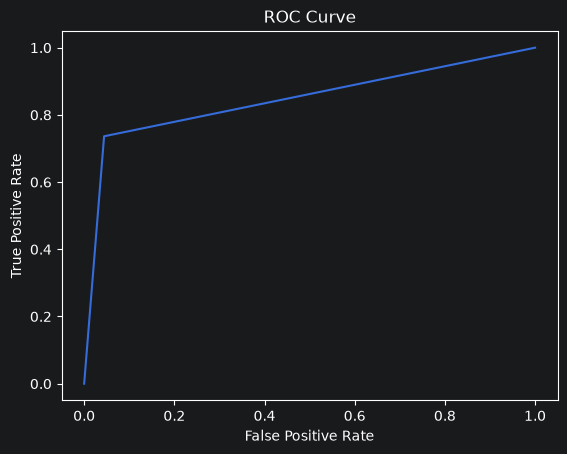

In [43]:
fpr, tpr, _ = roc_curve(y_test, predictions)

plt.clf()
plt.plot(fpr, tpr)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.show()

In [44]:
f1_score(y_test, predictions)

0.726457399103139

In [45]:
fbeta_score(y_test, predictions, beta=0.5)

0.7206405693950177

In [49]:
fbeta_score(y_test, predictions, beta=1.5)

0.7302357836338419

In [54]:
clf = DecisionTreeClassifier(criterion='gini', max_depth=10, random_state=2021)
scores = cross_val_score(clf, X, y, cv=10)
print(scores)
print("RESULT: %0.2f accuracy with a standard deviation of %0.2f" % (scores.mean(), scores.std()))

USING A DECISION TREE WITH cross_val_score (MEAN ACCURACY)...
[0.94011976 0.93113772 0.93712575 0.92792793 0.94894895 0.95195195
 0.93393393 0.93093093 0.93693694 0.95495495]
RESULT: 0.94 accuracy with a standard deviation of 0.01


## T3:
Obtain the model's confusion matrices and analyze them critically. What conclusions can be drawn?

In [67]:
X

,VMail Message,Day Mins,Eve Mins,Night Mins,Intl Mins,CustServ Calls,Day Calls,Day Charge,Eve Calls,Eve Charge,Night Calls,Night Charge,Intl Calls,Intl Charge,Account Length,Int'l Plan,VMail Plan
0,25,265.1,197.4,244.7,10.0,1,110,45.07,99,16.78,91,11.01,3,2.70,128,0,1
1,26,161.6,195.5,254.4,13.7,1,123,27.47,103,16.62,103,11.45,3,3.70,107,0,1
2,0,243.4,121.2,162.6,12.2,0,114,41.38,110,10.30,104,7.32,5,3.29,137,0,0
3,0,299.4,61.9,196.9,6.6,2,71,50.90,88,5.26,89,8.86,7,1.78,84,1,0
4,0,166.7,148.3,186.9,10.1,3,113,28.34,122,12.61,121,8.41,3,2.73,75,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3328,36,156.2,215.5,279.1,9.9,2,77,26.55,126,18.32,83,12.56,6,2.67,192,0,1
3329,0,231.1,153.4,191.3,9.6,3,57,39.29,55,13.04,123,8.61,4,2.59,68,0,0
3330,0,180.8,288.8,191.9,14.1,2,109,30.74,58,24.55,91,8.64,6,3.81,28,0,0
3331,0,213.8,159.6,139.2,5.0,2,105,36.35,84,13.57,137,6.26,10,1.35,184,1,0


In [84]:
from sklearn.model_selection import KFold

clf = DecisionTreeClassifier(criterion='gini', max_depth=10, random_state=2021)
scores = []
kf = KFold(n_splits=10)
for train, test in kf.split(X):
    clf.fit(X.loc[train,:], y.loc[train,:])
    score = clf.score(X.loc[test,:], y.loc[test,:])
    scores.append(score)
    y_predicted = clf.predict(X.loc[test,:])
    print("Confusion Matrix:")
    print(confusion_matrix(y.loc[test,:], y_predicted))
    print(score)
print("RESULT: %0.2f accuracy with a standard deviation of %0.2f" % (np.mean(scores), np.std(scores)))


Confusion Matrix:
[[283   6]
 [ 15  30]]
0.937125748502994
Confusion Matrix:
[[281   5]
 [ 13  35]]
0.9461077844311377
Confusion Matrix:
[[289   8]
 [ 10  27]]
0.9461077844311377
Confusion Matrix:
[[291   3]
 [ 15  24]]
0.9459459459459459
Confusion Matrix:
[[285   6]
 [ 13  29]]
0.9429429429429429
Confusion Matrix:
[[267   5]
 [ 15  46]]
0.93993993993994
Confusion Matrix:
[[282   9]
 [ 14  28]]
0.9309309309309309
Confusion Matrix:
[[269   3]
 [ 17  44]]
0.93993993993994
Confusion Matrix:
[[265   7]
 [ 26  35]]
0.9009009009009009
Confusion Matrix:
[[280   6]
 [  9  38]]
0.954954954954955
RESULT: 0.94 accuracy with a standard deviation of 0.01


## Conclusões:

As matrizes mostram que o modelo é bom a identificar quem fica e mais fraco a identificar quem sai. Há uma accuracy alta (0,94), mas ela esconde isso.

Somando as 10 matrizes (linhas = real, colunas = previsto, como o sklearn as mostra), obtenho:

	Prev. 0 (fica)	Prev. 1 (sai)
Real 0	2792 (TN)	58 (FP)
Real 1	147 (FN)	336 (TP)

O total dá 3333, que é o número de clientes do dataset, por isso a soma está certa.

Conclusões que podes tirar

1. A accuracy engana por causa do desbalanceamento. Só 483 dos 3333 clientes (14,5%) saíram. Um modelo que previsse sempre “fica” teria cerca de 85,5% de accuracy sem aprender nada. Os 93,9% do teu modelo são melhores do que isso, mas a diferença é menor do que o número parece indicar.

2. A classe “fica” é muito bem prevista. O recall é 2792/2850 ≈ 98%, e só 58 clientes que ficaram foram dados como saídas.

3. A classe “sai” é o ponto fraco. O recall do churn é 336/483 ≈ 70%, o que significa que o modelo deixa escapar cerca de 3 em cada 10 clientes que realmente saem (147 falsos negativos). A precision é 336/394 ≈ 85%: quando prevê que um cliente vai sair, acerta em cerca de 85% dos casos.

4. O tipo de erro dominante é o falso negativo. Há 147 FN contra 58 FP, ou seja, o modelo erra mais por “não avisar” do que por “avisar sem necessidade”. Para uma operadora, isto pesa: o objetivo da ficha é antecipar a saída para poder oferecer algo ao cliente, e esses 147 clientes saem sem ninguém os ter tentado reter. Perder um cliente costuma custar mais do que fazer uma oferta a quem ia ficar, por isso aqui o FN é, em geral, o erro mais caro. Isto depende dos custos reais da operadora, que a ficha não dá.

5. O modelo é estável, mas o recall varia entre folds. A accuracy anda entre 0,90 e 0,95 (desvio-padrão de 0,01). O recall do churn varia mais: no fold 9 é 35/61 ≈ 57% (o pior, também com a accuracy mais baixa, 0,90) e no fold 10 é 38/47 ≈ 81%. Isto mostra que a capacidade de detetar churn depende bastante dos clientes que calham em cada fold, o que justifica usar cross validation em vez de um único hold-out.

6. A accuracy e a f1_macro contam histórias diferentes. Com os teus números, o F1 da classe churn é cerca de 0,77 e o da classe “fica” cerca de 0,97, o que dá uma f1_macro por volta de 0,87, claramente abaixo dos 0,94 de accuracy. É por isso que a ficha pede as duas métricas.

## T4:
Change the hyperparameters of the Decision Tree (criterion and max_depth). What variation in model
performance is underlying these changes?

In [85]:
# Hyperparameter changed: Citerion -> Log Loss
clf = DecisionTreeClassifier(criterion='log_loss', max_depth=10, random_state=2021)
scores = cross_val_score(clf, X, y, cv=10)
print(scores)
print("RESULT: %0.2f accuracy with a standard deviation of %0.2f" % (scores.mean(), scores.std()))

[0.91916168 0.94610778 0.93712575 0.92792793 0.94894895 0.94594595
 0.94294294 0.94294294 0.92792793 0.95195195]
RESULT: 0.94 accuracy with a standard deviation of 0.01


In [86]:
# Hyperparameter changed: Citerion -> Entropy
clf = DecisionTreeClassifier(criterion='entropy', max_depth=10, random_state=2021)
scores = cross_val_score(clf, X, y, cv=10)
print(scores)
print("RESULT: %0.2f accuracy with a standard deviation of %0.2f" % (scores.mean(), scores.std()))

[0.91916168 0.94610778 0.93712575 0.92792793 0.94894895 0.94594595
 0.94294294 0.94294294 0.92792793 0.95195195]
RESULT: 0.94 accuracy with a standard deviation of 0.01


In [87]:
# Hyperparameter changed: MaxDepth -> 12
clf = DecisionTreeClassifier(criterion='gini', max_depth=12, random_state=2021)
scores = cross_val_score(clf, X, y, cv=10)
print(scores)
print("RESULT: %0.2f accuracy with a standard deviation of %0.2f" % (scores.mean(), scores.std()))

[0.92215569 0.93712575 0.93413174 0.93093093 0.94594595 0.93993994
 0.93093093 0.91291291 0.93693694 0.94594595]
RESULT: 0.93 accuracy with a standard deviation of 0.01


In [88]:
# Hyperparameter changed: MaxDepth -> 8
clf = DecisionTreeClassifier(criterion='gini', max_depth=8, random_state=2021)
scores = cross_val_score(clf, X, y, cv=10)
print(scores)
print("RESULT: %0.2f accuracy with a standard deviation of %0.2f" % (scores.mean(), scores.std()))

[0.94311377 0.93413174 0.94011976 0.93393393 0.95495495 0.95495495
 0.93993994 0.93393393 0.93393393 0.95495495]
RESULT: 0.94 accuracy with a standard deviation of 0.01


In [89]:
# Hyperparameter changed: class_weight="balanced"
clf = DecisionTreeClassifier(criterion='gini', max_depth=10, class_weight="balanced", random_state=2021)
scores = cross_val_score(clf, X, y, cv=10)
print(scores)
print("RESULT: %0.2f accuracy with a standard deviation of %0.2f" % (scores.mean(), scores.std()))

[0.91616766 0.9251497  0.91616766 0.91591592 0.93093093 0.94294294
 0.92792793 0.91291291 0.91591592 0.95495495]
RESULT: 0.93 accuracy with a standard deviation of 0.01


In [90]:
from sklearn.model_selection import cross_validate

criterios = ["gini", "entropy", "log_loss"]
profundidades = [1, 2, 3, 4, 5, 7, 10, 15, 20, None]   # None = sem limite

linhas = []
for crit in criterios:
    for d in profundidades:
        m = DecisionTreeClassifier(criterion=crit, max_depth=d, random_state=2021)
        r = cross_validate(m, X, y, scoring=["accuracy", "f1_macro"])
        linhas.append({
            "criterion": crit,
            "max_depth": "None" if d is None else d,
            "accuracy": r["test_accuracy"].mean(),
            "acc_std": r["test_accuracy"].std(),
            "f1_macro": r["test_f1_macro"].mean(),
            "f1_std": r["test_f1_macro"].std(),
        })

resultados = pd.DataFrame(linhas)
print(resultados.round(3).to_string(index=False))

melhor = resultados.loc[resultados["f1_macro"].idxmax()]
print(f"\nMelhor configuração por f1_macro: criterion={melhor['criterion']}, "
      f"max_depth={melhor['max_depth']} -> f1_macro={melhor['f1_macro']:.3f}, "
      f"accuracy={melhor['accuracy']:.3f}")

criterion max_depth  accuracy  acc_std  f1_macro  f1_std
     gini         1     0.867    0.007     0.644   0.014
     gini         2     0.878    0.004     0.720   0.028
     gini         3     0.902    0.006     0.742   0.026
     gini         4     0.916    0.004     0.798   0.010
     gini         5     0.933    0.003     0.854   0.009
     gini         7     0.943    0.004     0.875   0.010
     gini        10     0.940    0.005     0.871   0.012
     gini        15     0.929    0.010     0.854   0.019
     gini        20     0.914    0.011     0.831   0.018
     gini      None     0.912    0.010     0.828   0.016
  entropy         1     0.858    0.013     0.596   0.070
  entropy         2     0.872    0.010     0.683   0.064
  entropy         3     0.896    0.016     0.743   0.019
  entropy         4     0.914    0.007     0.795   0.014
  entropy         5     0.934    0.005     0.856   0.013
  entropy         7     0.940    0.006     0.866   0.015
  entropy        10     0.938  